In [69]:
import sys
sys.path.append("../")
from collections import defaultdict

import pyarrow.feather as feather
import numpy as np
import itertools
from pathlib import Path
from utils import *
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

import networkx as nx

from tqdm.auto import tqdm

import seaborn as sns
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

In [2]:
DATA_DIR = Path("../data/burnin_diagnostic/")

snap_df = feather.read_feather(DATA_DIR / "burnin_snapshots.arrow")
casc_df = feather.read_feather(DATA_DIR / "burnin_cascades.arrow")

cfg = {}
with open(DATA_DIR / "diagnostic_config.txt") as f:
    for line in f:
        k, v = line.strip().split(" = ")
        try:    cfg[k] = float(v)
        except: cfg[k] = v

BURN_IN   = int(cfg["burn_in_length"])
TRUE_PREV = 1.0 - cfg["p_fake"]
TRUE_TPR  = cfg["tpr"]
TRUE_FPR  = cfg["fpr"]

PARAM_STR = (f"v_cost={cfg['v_cost']}  loss={cfg['rep_loss']}  "
             f"tpr={cfg['tpr']}  fpr={cfg['fpr']}  p_fake={cfg['p_fake']}")

print(f"Reps        : {snap_df['rep_id'].nunique()}")
print(f"Timepoints  : {snap_df['cascade_id'].nunique()}")
print(f"Burn-in     : {BURN_IN} cascades")
print(f"Parameters: " + PARAM_STR)

Reps        : 50
Timepoints  : 2200
Burn-in     : 2000 cascades
Parameters: v_cost=0.01  loss=3.0  tpr=0.85  fpr=0.1  p_fake=0.2


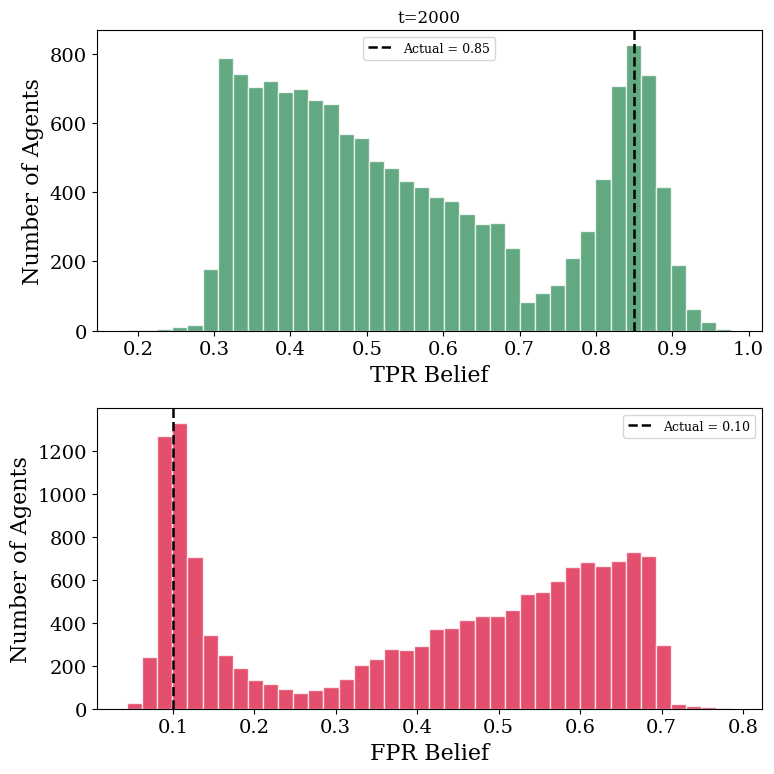

In [3]:
all_cids        = sorted(snap_df["cascade_id"].unique())
t_burnin_actual = min(all_cids, key=lambda x: abs(x - BURN_IN))
timepoints      = [t_burnin_actual]
t_labels        = {t_burnin_actual: f"t={t_burnin_actual}"}

dist_panels = [
    ("tpr_mean",  "Number of Agents", TRUE_TPR,  "seagreen", "TPR Belief"),
    ("fpr_mean",  "Number of Agents", TRUE_FPR,  "crimson", "FPR Belief"),
]

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey="row")

for row, (col, ylabel, truth, color, xlabel) in enumerate(dist_panels):
    for col_i, t in enumerate(timepoints):
        ax = axes[row]
        data = snap_df[snap_df["cascade_id"] == t][col].dropna()
        ax.hist(data, bins=40, color=color, alpha=0.75, edgecolor="white")
        if truth is not None:
            ax.axvline(truth, color="black", lw=1.8, ls="--", label=f"Actual = {truth:.2f}")
            ax.legend(fontsize=9)
        if row == 0:
            ax.set_title(t_labels[t], fontsize=12)
        if col_i == 0:
            ax.set_ylabel(ylabel)
        ax.set_xlabel(xlabel)

fig.tight_layout()
plt.show()

In [4]:
start = snap_df[snap_df["cascade_id"]==1]
end = snap_df[snap_df["cascade_id"]==2000]

In [5]:
end.head()

,rep_id,cascade_id,phase,node_id,true_mean,tpr_mean,fpr_mean,true_n,tpr_n,fpr_n,mean_trust,mean_trust_n,node_degree,betweenness,closeness,eigenvector,verify_count
599700,1,2000,burnin,1,0.848311,0.382591,0.473137,1722.0,2.0,2.0,0.765742,67.993519,26,0.062780,0.432081,0.198971,0
599701,1,2000,burnin,2,0.848351,0.832017,0.129149,1721.0,46.0,206.0,0.767602,48.882930,37,0.113859,0.458589,0.292342,248
599702,1,2000,burnin,3,0.849465,0.612081,0.612181,1721.0,2.0,2.0,0.833036,67.489777,26,0.077738,0.427754,0.186547,0
599703,1,2000,burnin,4,0.848773,0.370871,0.388166,1720.0,2.0,2.0,0.816479,33.609591,54,0.235035,0.496678,0.385482,0
599704,1,2000,burnin,5,0.849292,0.467606,0.474369,1720.0,2.0,2.0,0.788541,49.925348,36,0.116778,0.452345,0.248754,0


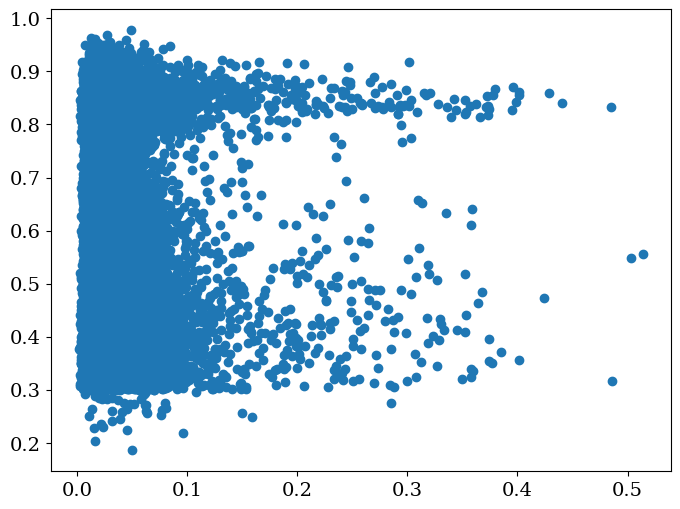

In [6]:
plt.scatter(
    end["eigenvector"],
    end["tpr_mean"]
)

plt.show()

In [15]:
not_verifying = end[end["verify_count"]==0]
verifying = end[end["verify_count"]!=0]

idx_not_verifying = not_verifying[["rep_id", "node_id"]]
idx_verifying = verifying[["rep_id", "node_id"]]

start_not_verifying = start.merge(idx_not_verifying, on=["rep_id", "node_id"])
start_verifying = start.merge(idx_verifying, on=["rep_id", "node_id"])

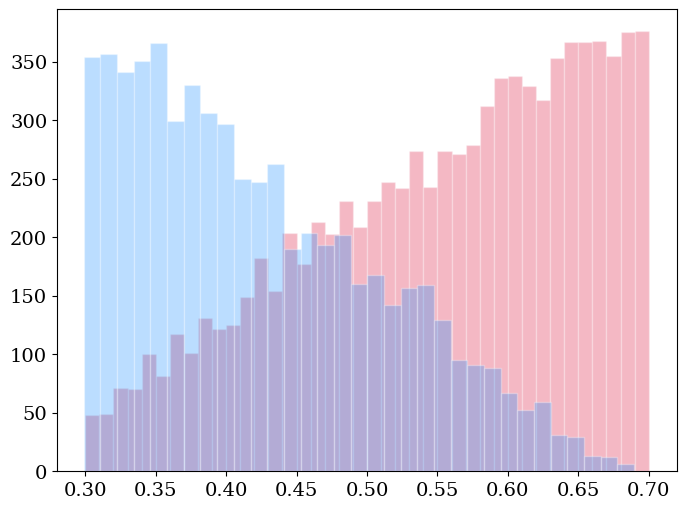

In [22]:
plt.hist(start_not_verifying["fpr_mean"], bins=40, color="crimson", alpha=0.3, edgecolor="white")
plt.hist(start_verifying["fpr_mean"], bins=40, color="dodgerblue", alpha=0.3, edgecolor="white")
plt.xlim(0.28, 0.72)
plt.show()

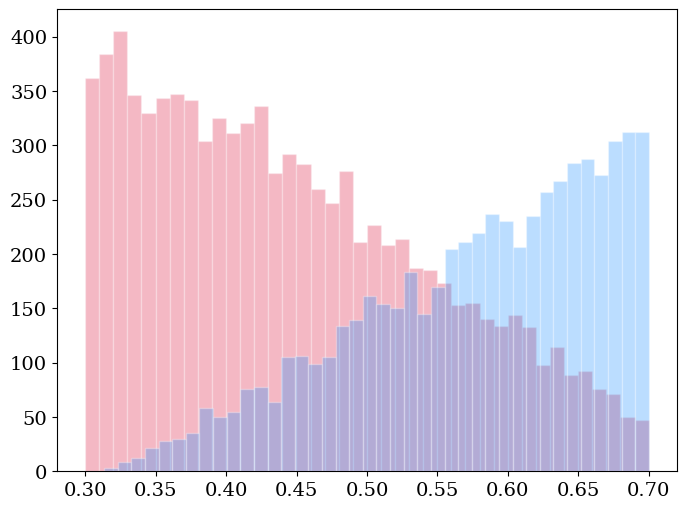

In [23]:
plt.hist(start_not_verifying["tpr_mean"], bins=40, color="crimson", alpha=0.3, edgecolor="white")
plt.hist(start_verifying["tpr_mean"], bins=40, color="dodgerblue", alpha=0.3, edgecolor="white")
plt.show()

In [52]:
X = start[["tpr_mean", "fpr_mean"]].values

X = np.column_stack([X, end[["verify_count"]].values])

y = end["tpr_mean"].values

model = LinearRegression().fit(X, y)
print(f"R²: {r2_score(y, model.predict(X)):.3f}")
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_:.3f}")

R²: 0.775
Coefficients: [ 1.05305044e+00 -2.70951677e-01  3.12773504e-04]
Intercept: 0.144


In [39]:
X = start[["tpr_mean", "fpr_mean"]].values

y = end["tpr_mean"].values

model = LinearRegression().fit(X, y)
print(f"R²: {r2_score(y, model.predict(X)):.3f}")
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_:.3f}")

R²: 0.659
Coefficients: [ 1.27306881 -0.49273456]
Intercept: 0.179


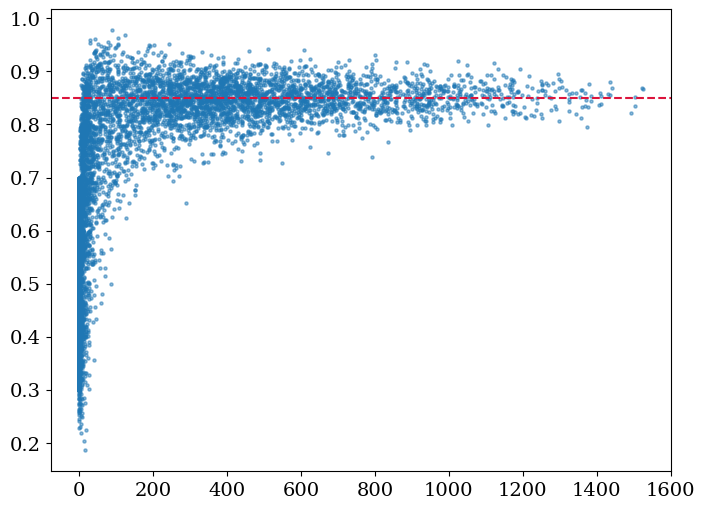

In [65]:
plt.scatter(
    end["verify_count"],
    end["tpr_mean"],
    s=5,
    alpha=0.5
)

plt.axhline(TRUE_TPR, linestyle="dashed", color="crimson")

plt.show()

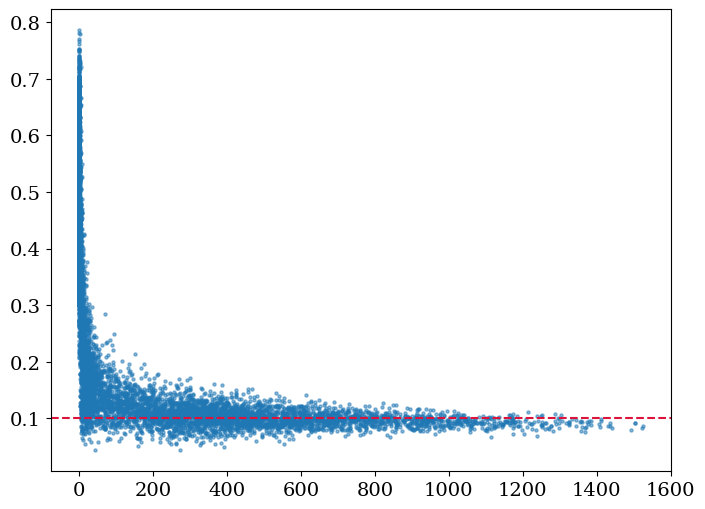

In [67]:
plt.scatter(
    end["verify_count"],
    end["fpr_mean"],
    s=5,
    alpha=0.5
)

plt.axhline(TRUE_FPR, linestyle="dashed", color="crimson")

plt.show()

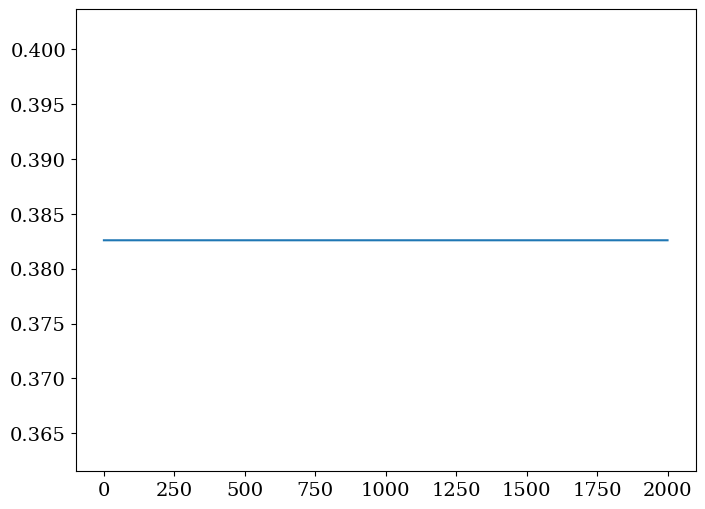

In [74]:
plt.plot(
    np.arange(2000),
    list(snap_df[(snap_df["node_id"]==1)&(snap_df["rep_id"]==1)]["tpr_mean"])[:2000])
plt.show()